<a href="https://colab.research.google.com/github/Destian0870/244107020203-mobile-course/blob/main/Week3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Mengubah tingkat kecerahan citra 
----------------------------------
Masukkan nilai kecerahan: 30


/tmp/ipykernel_2792/1279826076.py:18: RuntimeWarning: overflow encountered in scalar add
  brightness_image[y,x,c] = np.clip(original[y,x,c] + brightness, 0, 255)


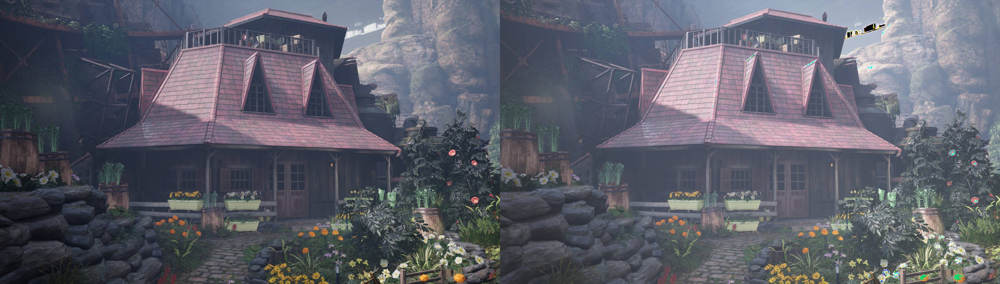

In [ ]:
import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow

print(' Mengubah tingkat kecerahan citra ')
print('----------------------------------')
try:
    brightness = int(input('Masukkan nilai kecerahan: '))
except ValueError:
    print('Error, not a number')

original = cv.imread('House.jpg')
brightness_image = np.zeros(original.shape, original.dtype)

for y in range(original.shape[0]):
    for x in range(original.shape[1]):
        for c in range(original.shape[2]):
            brightness_image[y,x,c] = np.clip(original[y,x,c] + brightness, 0, 255)

final_frame = cv.hconcat((original, brightness_image))
cv2_imshow(final_frame)

Tugas Praktikum

1.


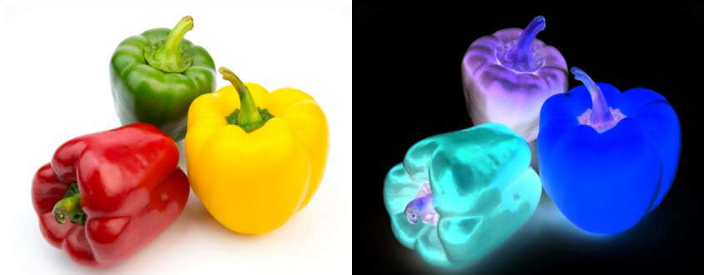

In [ ]:
import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow

img = cv.imread('peppers.png')

img_inverse = 255 - img

final = cv.hconcat((img, img_inverse))
cv2_imshow(final)

2.

Mengubah kontras dan tingkat kecerahan citra
-----------------------------------------
Masukkan tingkat kecerahan: 10
Masukkan kontras: 1.5


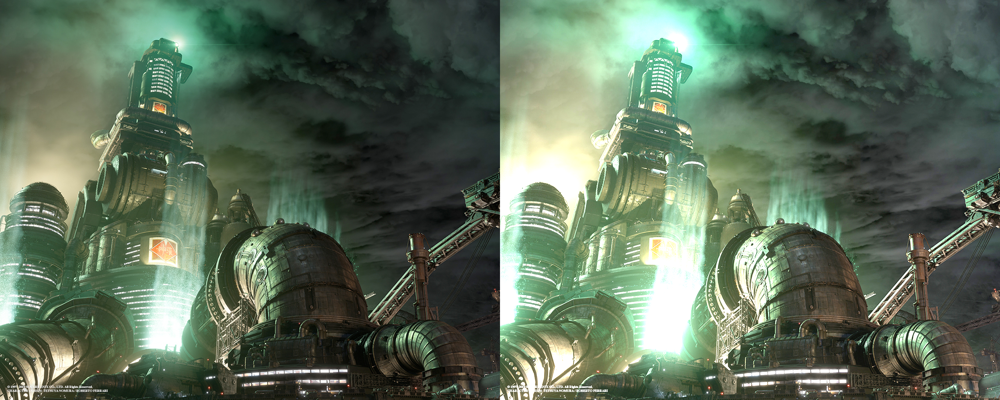

In [ ]:
import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow

print('Mengubah kontras dan tingkat kecerahan citra')
print('-----------------------------------------')
brightness = int(input('Masukkan tingkat kecerahan: '))
contrast = float(input('Masukkan kontras: '))

img = cv.imread('Sky.jpg')

img_contrast = cv.convertScaleAbs(img, alpha=contrast, beta=brightness)

final = cv.hconcat((img, img_contrast))
cv2_imshow(final)

3.

Masukkan nilai kecerahan (c): 50


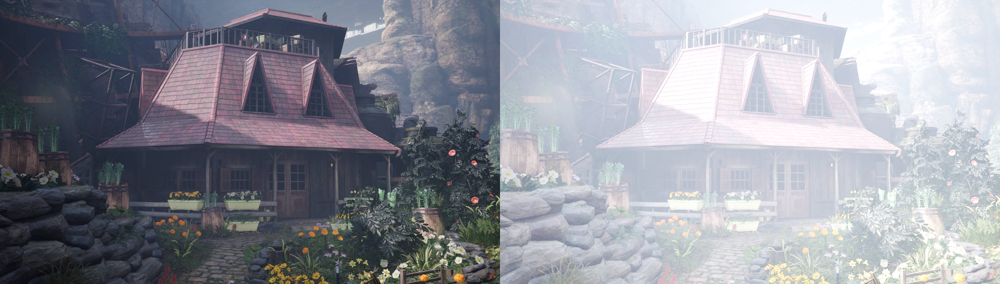

In [ ]:
import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow

brightness = float(input('Masukkan nilai kecerahan (c): '))
img = cv.imread('House.jpg')

img_float = img.astype(np.float32)
log_img = brightness * np.log1p(img_float)
log_img = np.clip(log_img, 0, 255).astype(np.uint8)

final = cv.hconcat((img, log_img))
cv2_imshow(final)

4.

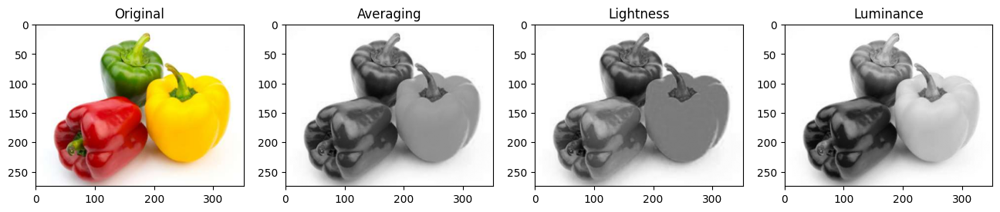

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('peppers.png')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

r, g, b = img_rgb[:,:,0], img_rgb[:,:,1], img_rgb[:,:,2]

gray_avg = ((r.astype(int) + g.astype(int) + b.astype(int)) // 3).astype('uint8')

gray_light = ((np.maximum.reduce([r, g, b]).astype(int) + np.minimum.reduce([r, g, b]).astype(int)) // 2).astype('uint8')

gray_lum = (0.21 * r + 0.72 * g + 0.07 * b).astype('uint8')

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_rgb)
axes[0].set_title("Original")

axes[1].imshow(gray_avg, cmap='gray')
axes[1].set_title("Averaging")

axes[2].imshow(gray_light, cmap='gray')
axes[2].set_title("Lightness")

axes[3].imshow(gray_lum, cmap='gray')
axes[3].set_title("Luminance")

plt.show()

5.

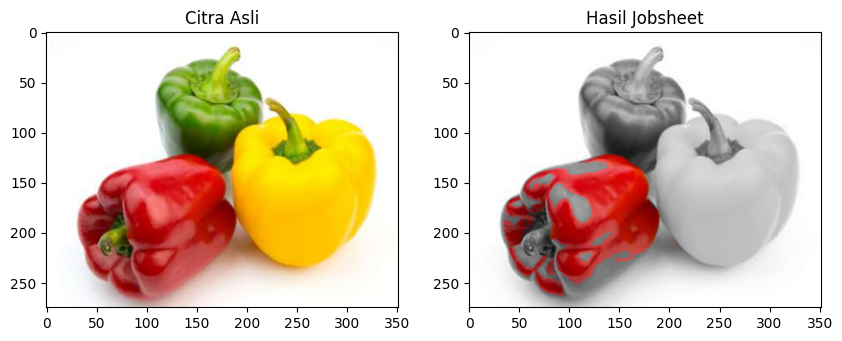

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('peppers.png')
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

lower_red1 = np.array([0, 160, 100])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([170, 160, 100])
upper_red2 = np.array([180, 255, 255])

mask = cv.inRange(hsv, lower_red1, upper_red1) | cv.inRange(hsv, lower_red2, upper_red2)

gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)
gray_3ch = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)

result = np.where(mask[:, :, None] == 255, img_rgb, gray_3ch)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Citra Asli")

axes[1].imshow(result)
axes[1].set_title("Hasil Jobsheet")

plt.show()

6.

 Gamma Correction pada citra 
----------------------------
Masukkan nilai Gamma: 0.5


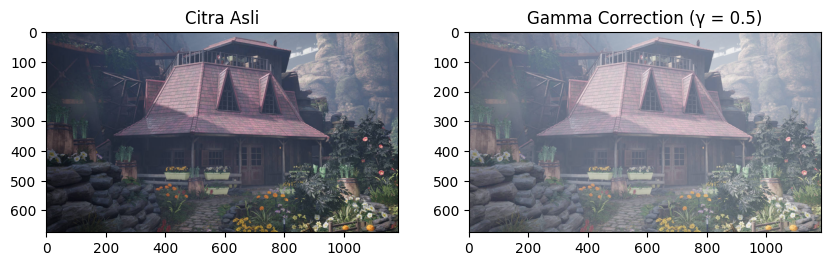

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print(' Gamma Correction pada citra ')
print('----------------------------')
try:
    gamma = float(input('Masukkan nilai Gamma: '))

    img = cv.imread('House.jpg')
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    gamma_corrected = np.array(255 * (img_rgb / 255.0) ** gamma, dtype='uint8')

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_rgb)
    axes[0].set_title("Citra Asli")

    axes[1].imshow(gamma_corrected)
    axes[1].set_title(f"Gamma Correction (γ = {gamma})")

    plt.show()

except ValueError:
    print('Error, not a number')

7.

Masukkan bit depth tujuan (1-8): 3
Bit depth awal   : 8 bit
Bit depth tujuan : 3 bit
Jumlah level     : 8


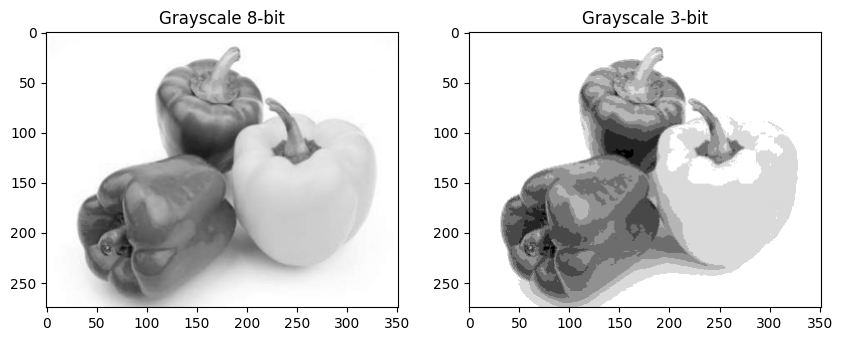

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Input bit depth dari pengguna
bit_depth = int(input('Masukkan bit depth tujuan (1-8): '))

# 2. Cetak teks informasi persis seperti pada jobsheet
print(f'Bit depth awal   : 8 bit')
print(f'Bit depth tujuan : {bit_depth} bit')
print(f'Jumlah level     : {2**bit_depth}')

img = cv.imread('peppers.png', cv.IMREAD_GRAYSCALE)

levels = 2 ** bit_depth
step = 256 / levels
depth_image = np.floor(img / step) * (255 / (levels - 1))
depth_image = depth_image.astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title("Grayscale 8-bit")

axes[1].imshow(depth_image, cmap='gray')
axes[1].set_title(f"Grayscale {bit_depth}-bit")

plt.show()

8.

In [ ]:
import cv2 as cv
import numpy as np
import os

if not os.path.exists('noises'):
    os.makedirs('noises')

img = cv.imread('Galaxy.jpg')

if img is not None:
    for i in range(1, 101):
        noise = np.random.normal(0, 25, img.shape).astype(np.float32)
        noisy_img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

        cv.imwrite(f'noises/noise_{i}.jpg', noisy_img)

    print("Selesai! 100 gambar noise berhasil dibuat di folder 'noises'.")
else:
    print("File 'galaxy.jpg' tidak ditemukan! Silakan upload dulu 'galaxy.jpg' ke panel sebelah kiri Google Colab.")

Selesai! 100 gambar noise berhasil dibuat di folder 'noises'.


=== HASIL AVERAGE DENOISING & PSNR ===
Jumlah Citra: 10 | PSNR: 32.12 dB
Jumlah Citra: 20 | PSNR: 33.90 dB
Jumlah Citra: 40 | PSNR: 35.17 dB
Jumlah Citra: 80 | PSNR: 35.98 dB
Jumlah Citra: 100 | PSNR: 36.16 dB


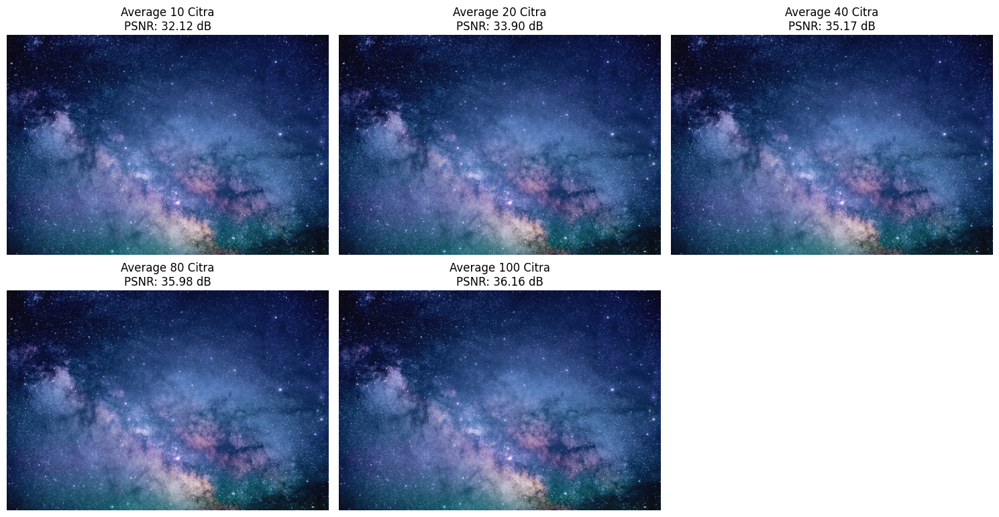

In [ ]:
import cv2 as cv
import numpy as np
import glob
import matplotlib.pyplot as plt

def PSNR(img1, img2):
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)

    mse = np.mean((img1 - img2) ** 2)
    if mse == 0:
        return 100
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

img_asli = cv.imread('Galaxy.jpg')

if img_asli is None:
    print("ERROR: File 'Galaxy.jpg' tidak ditemukan di root Colab!")
    print("Pastikan kamu sudah mengunggah 'galaxy.jpg' atau menjalankan script pembuat noise lebih dahulu.")
else:
    cv_img = []
    for img_path in sorted(glob.glob('noises/*.jpg')):
        n = cv.imread(img_path)
        if n is not None:
            cv_img.append(n)

    if len(cv_img) == 0:
        print("ERROR: Folder 'noises' kosong atau tidak ditemukan!")
    else:

        def average_denoising(images, num_images):
            selected_images = images[:num_images]
            avg_img = np.mean(selected_images, axis=0).astype(np.uint8)
            return avg_img

        jumlah_citra = [10, 20, 40, 80, 100]

        print("=== HASIL AVERAGE DENOISING & PSNR ===")
        plt.figure(figsize=(15, 8))

        for i, N in enumerate(jumlah_citra):
            denoised_img = average_denoising(cv_img, N)

            nilai_psnr = PSNR(img_asli, denoised_img)

            print(f"Jumlah Citra: {N} | PSNR: {nilai_psnr:.2f} dB")

            plt.subplot(2, 3, i + 1)
            plt.imshow(cv.cvtColor(denoised_img, cv.COLOR_BGR2RGB))
            plt.title(f"Average {N} Citra\nPSNR: {nilai_psnr:.2f} dB")
            plt.axis('off')

        plt.tight_layout()
        plt.show()

9.

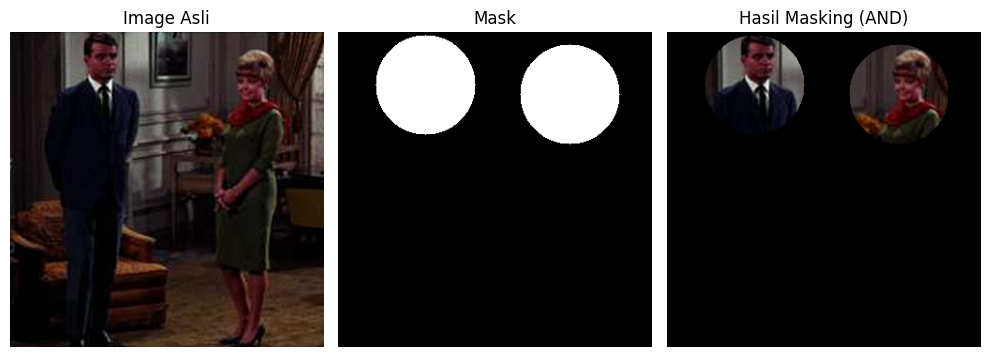

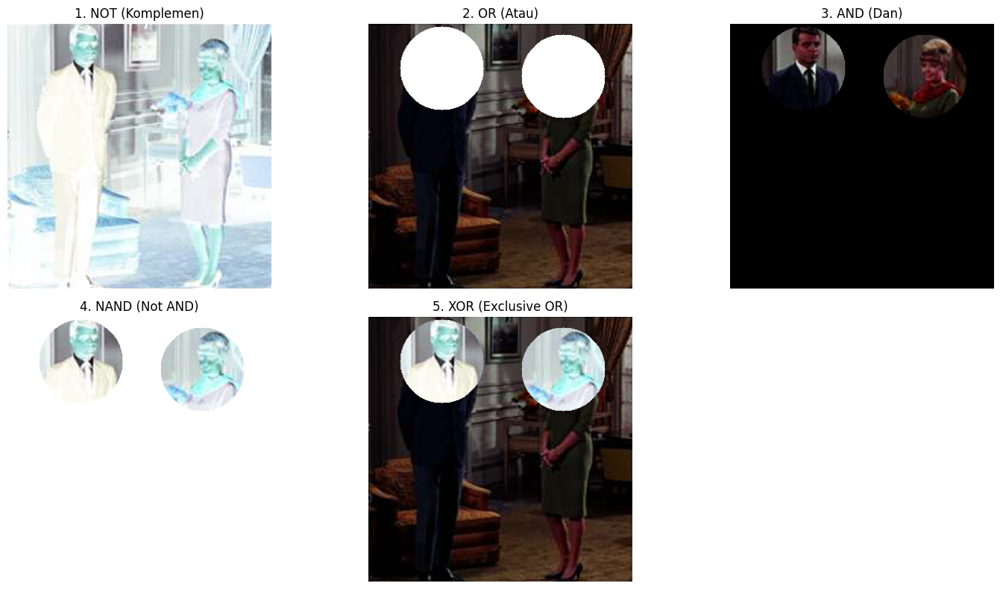

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('Couple.png')

if img is None:
    print("Error: File 'Couple.png' tidak ditemukan.")
else:
    h, w = img.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    r = int(min(h, w) * 0.16)
    center_pria = (int(w * 0.28), int(h * 0.17))
    center_wanita = (int(w * 0.74), int(h * 0.20))

    cv.circle(mask, center_pria, r, 255, -1)
    cv.circle(mask, center_wanita, r, 255, -1)

    mask_3ch = cv.cvtColor(mask, cv.COLOR_GRAY2BGR)

    res_not  = cv.bitwise_not(img)
    res_or   = cv.bitwise_or(img, mask_3ch)
    res_and  = cv.bitwise_and(img, mask_3ch)
    res_nand = cv.bitwise_not(res_and)
    res_xor  = cv.bitwise_xor(img, mask_3ch)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title("Image Asli")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv.cvtColor(res_and, cv.COLOR_BGR2RGB))
    plt.title("Hasil Masking (AND)")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    operators = [
        ("1. NOT (Komplemen)", res_not),
        ("2. OR (Atau)", res_or),
        ("3. AND (Dan)", res_and),
        ("4. NAND (Not AND)", res_nand),
        ("5. XOR (Exclusive OR)", res_xor)
    ]

    plt.figure(figsize=(15, 8))
    for idx, (title, res_img) in enumerate(operators):
        plt.subplot(2, 3, idx + 1)
        plt.imshow(cv.cvtColor(res_img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

10.

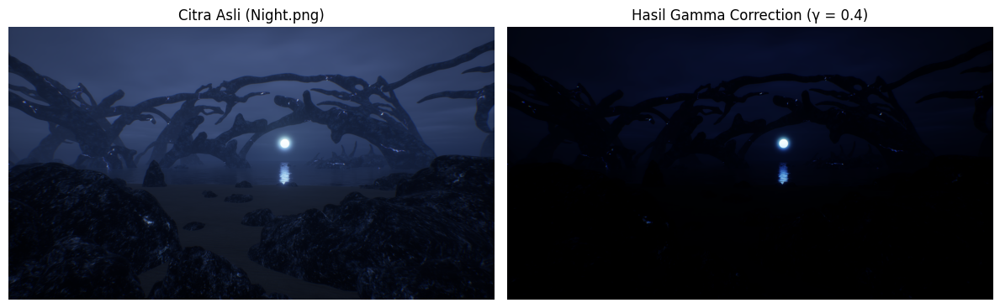

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar Night.png dari daftar file Colab kamu
img_malam = cv.imread('Night.png')

if img_malam is None:
    print("Error: File 'Night.png' tidak ditemukan. Pastikan nama filenya sesuai!")
else:
    # 2. Penerapan Gamma Correction (Gamma < 1.0 untuk menaikkan brightness area gelap)
    gamma = 0.4
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    img_hasil = cv.LUT(img_malam, table)

    # 3. Tampilkan Hasil Before dan After
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img_malam, cv.COLOR_BGR2RGB))
    plt.title('Citra Asli (Night.png)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(img_hasil, cv.COLOR_BGR2RGB))
    plt.title(f'Hasil Gamma Correction (γ = {gamma})')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

11.

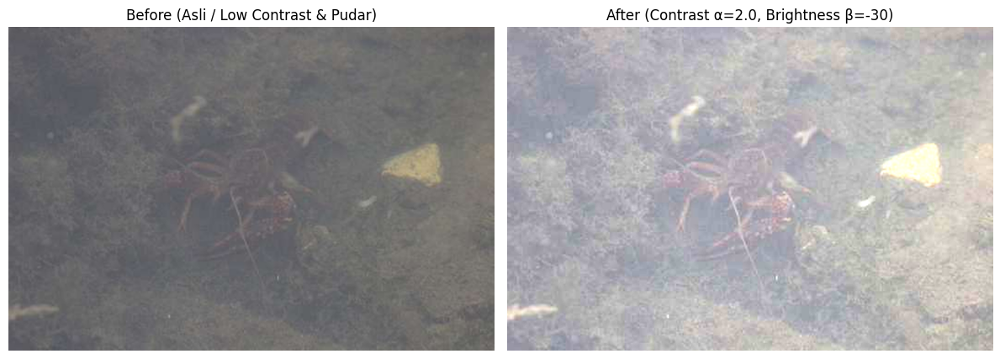

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar Soal11.png dari daftar file Colab kamu
crayfish = cv.imread('Soal11.png')

if crayfish is None:
    print("Error: File 'Soal11.png' tidak ditemukan. Pastikan nama filenya sesuai!")
else:
    # 2. Metode Perbaikan: Kombinasi Linear Contrast Stretching & Brightness Adjustment
    # Formula: output = alpha * input + beta
    alpha = 2.0   # Penguat kontras
    beta = -30    # Penyesuaian brightness (mengurangi warna pudar/kabut)

    # Terapkan transformasi linear
    crayfish_fixed = cv.convertScaleAbs(crayfish, alpha=alpha, beta=beta)

    # 3. Tampilkan Hasil Before - After
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(crayfish, cv.COLOR_BGR2RGB))
    plt.title('Before (Asli / Low Contrast & Pudar)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(crayfish_fixed, cv.COLOR_BGR2RGB))
    plt.title(f'After (Contrast α={alpha}, Brightness β={beta})')
    plt.axis('off')

    plt.tight_layout()
    plt.show()